# Assignment 2 — MLP vs GCN vs GraphSAGE vs GAT on Cora

In [1]:
import sys; sys.path.append("../src")
import pandas as pd
from data import load_cora, describe
from models import KINDS
from train import seed_all
from experiments import tune, final, summarize, depth_study, edge_study, error_analysis, make
import viz
pd.set_option("display.max_colwidth", 80)
seed_all(0)

c:\Users\PC\Documents\GNN-practical-assignments\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 1. Inspect the dataset
Nodes = papers, features = binary bag-of-words (row-normalised), edges = citations (treated as undirected), classes = 7 topics, split = standard Planetoid (140 / 500 / 1000).

nodes                     2708
undirected edges          5278
features (bag-of-words)   1433
classes                   7
train/val/test            (140, 500, 1000)
avg degree                3.9
isolated nodes            0
edge homophily            0.81
has self-loops            False


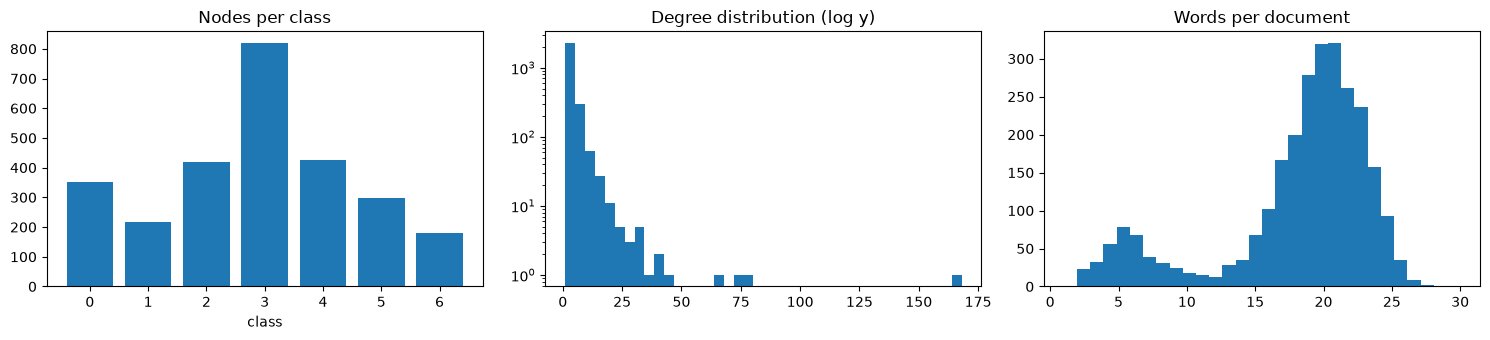

In [3]:
data = load_cora()
for k, v in describe(data).items(): print(f"{k:26s}{v}")
viz.plot_dataset(data)

## 2. Hyper-parameter tuning — identical budget (8 random configs, same configs for all), chosen by **validation** accuracy

MLP -> {'lr': 0.02, 'wd': 0.0005, 'hidden': 32, 'dropout': 0.3} | best val: 0.616
GCN -> {'lr': 0.02, 'wd': 0.001, 'hidden': 32, 'dropout': 0.5} | best val: 0.812
GraphSAGE -> {'lr': 0.02, 'wd': 0.001, 'hidden': 32, 'dropout': 0.5} | best val: 0.806
GAT -> {'lr': 0.01, 'wd': 0.001, 'hidden': 16, 'dropout': 0.5} | best val: 0.818


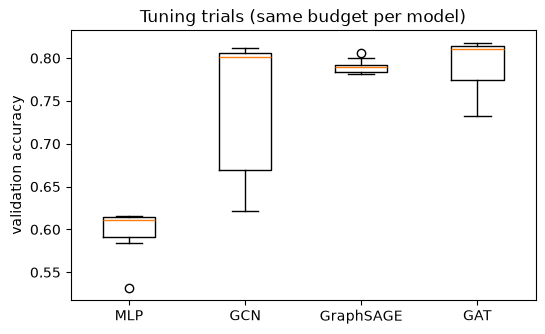

,lr,wd,hidden,dropout,val
1,0.02,0.0010,32,0.5,0.812
3,0.02,0.0005,32,0.3,0.810
2,0.01,0.0010,64,0.3,0.804


In [5]:
best, tables = {}, {}
for kind in KINDS:
    best[kind], tables[kind] = tune(kind, data, n_trials=8)
    print(kind, "->", best[kind], "| best val:", round(tables[kind].val.max(), 3))
viz.plot_tuning(tables)
display(tables["GCN"].head(3))

## 3. Final comparison — best config, 3 seeds, test set used here for the first time

,test_acc,macro_f1,train_time_s,params
model,,,,
MLP,0.587 ± 0.003,0.566 ± 0.002,18.04,46119
GCN,0.820 ± 0.004,0.807 ± 0.002,13.47,46119
GraphSAGE,0.802 ± 0.005,0.794 ± 0.004,34.11,92199
GAT,0.807 ± 0.013,0.800 ± 0.013,23.88,23109


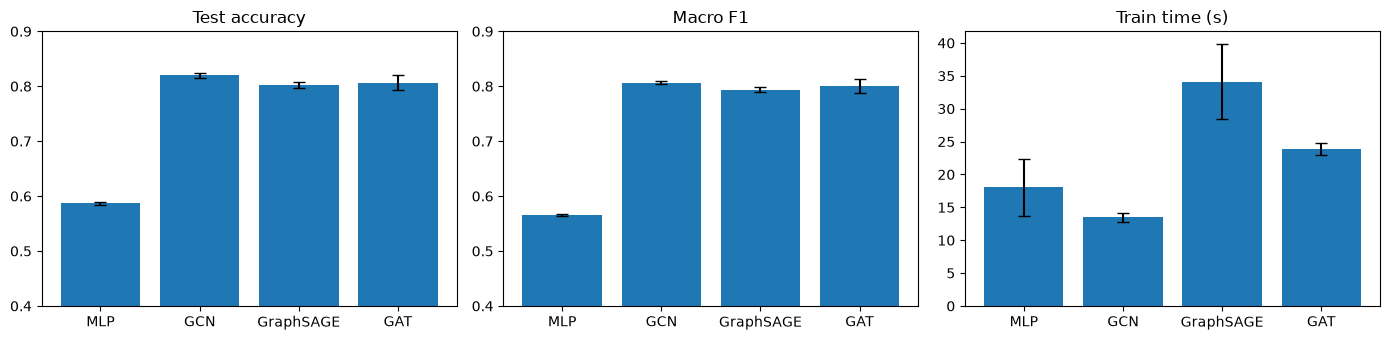

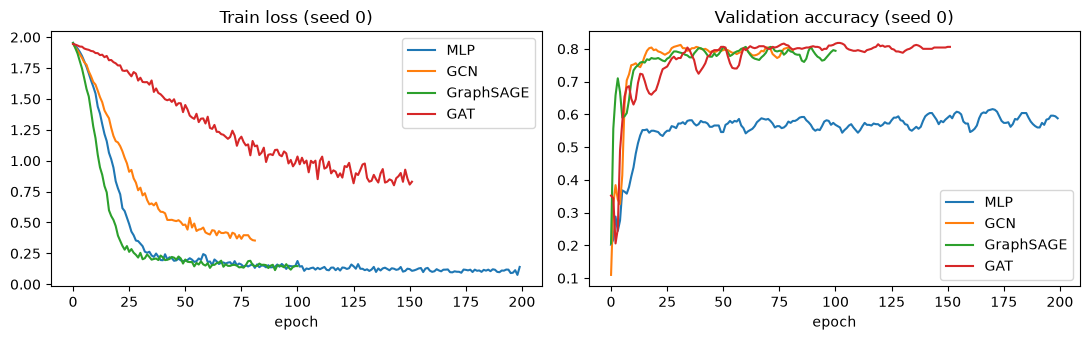

In [6]:
dfs, runs = [], {}
for kind in KINDS:
    df, r = final(kind, best[kind], data)
    dfs.append(df); runs[kind] = r
results = pd.concat(dfs)
display(summarize(results))
viz.plot_results(results)
viz.plot_curves({k: r[0] for k, r in runs.items()})

### 3b. Learned embeddings and confusion matrix
Left: 2-D PCA of each model's hidden-layer embeddings, coloured by true class. If the GNNs separate the classes better than the MLP, message passing is helping. Right: where the GCN confuses one topic for another on the test set.

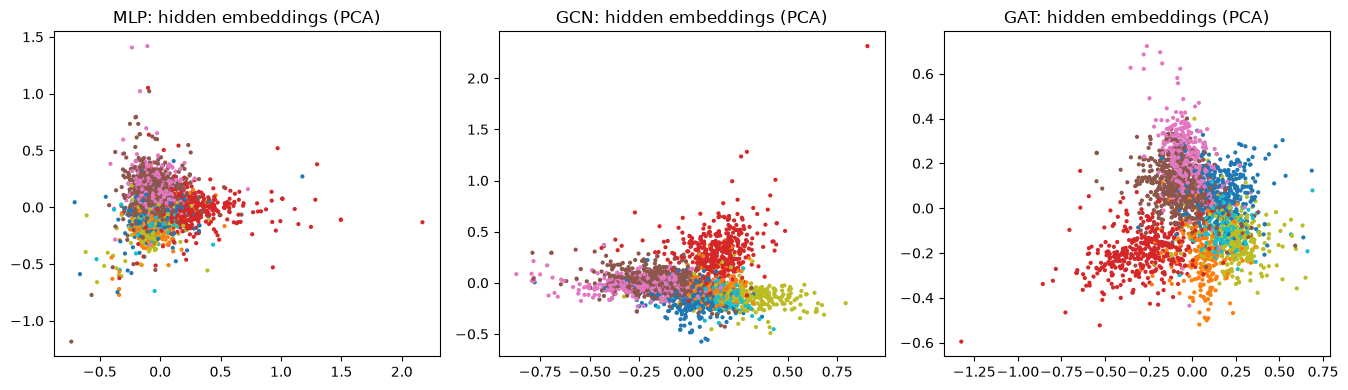

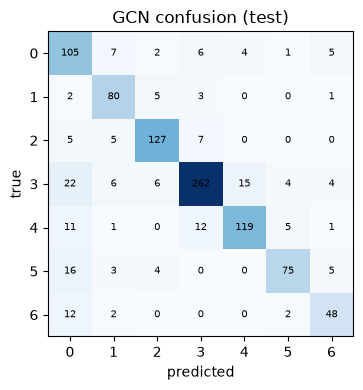

In [7]:
models = {k: r[0]["model"] for k, r in runs.items()}
viz.plot_embeddings({k: models[k] for k in ["MLP", "GCN", "GAT"]}, data)
viz.plot_confusion(models["GCN"], data, "GCN")

## 4. Depth study — accuracy and embedding similarity (over-smoothing)

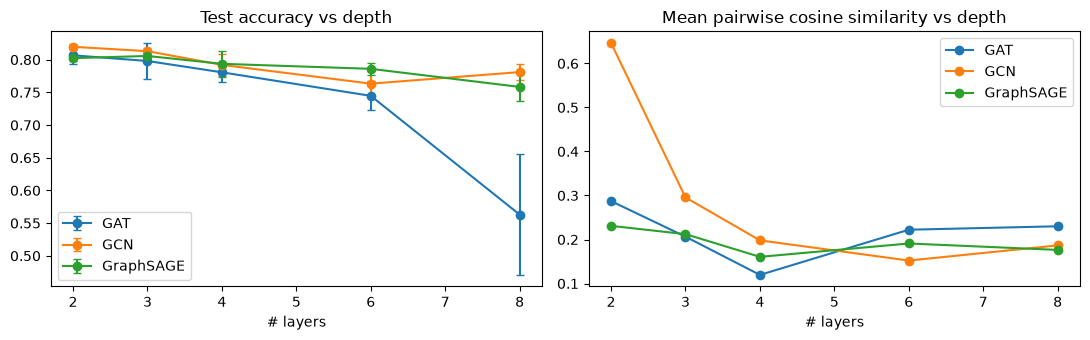

test_acc                  cos_sim                 
model      GAT    GCN GraphSAGE     GAT    GCN GraphSAGE
depth                                                   
2        0.807  0.820     0.802   0.287  0.647     0.231
3        0.798  0.813     0.806   0.206  0.296     0.212
4        0.781  0.792     0.794   0.120  0.198     0.161
6        0.745  0.763     0.786   0.222  0.152     0.191
8        0.563  0.781     0.758   0.230  0.187     0.176

In [8]:
gnns = ["GCN", "GraphSAGE", "GAT"]
depth_df = depth_study(gnns, best, data)
viz.plot_depth(depth_df)
display(depth_df.groupby(["model", "depth"])[["test_acc", "cos_sim"]].mean().round(3).unstack(0))

## 5. Edge-removal study (MLP = control, uses no edges)

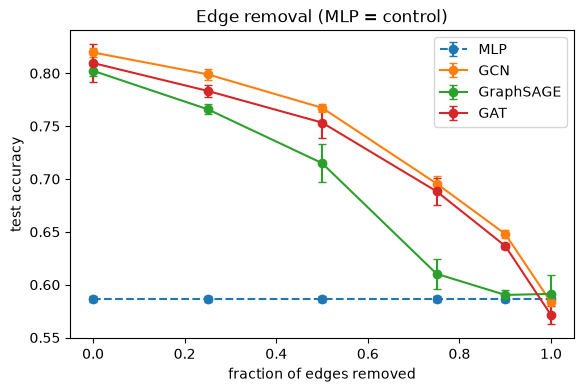

model,GAT,GCN,GraphSAGE,MLP
frac_removed,,,,
0.00,0.810,0.820,0.802,0.587
0.25,0.783,0.799,0.766,0.587
0.50,0.753,0.767,0.715,0.587
0.75,0.688,0.696,0.610,0.587
0.90,0.637,0.648,0.590,0.587
1.00,0.571,0.583,0.591,0.587


In [9]:
edge_df = edge_study(best, data)
viz.plot_edges(edge_df)
display(edge_df.groupby(["model", "frac_removed"]).test_acc.mean().unstack(0).round(3))

## 6. Error analysis — 5 most confident wrong test predictions of the best GNN

analysing: GAT


,node,true,gnn_pred,mlp_pred,conf,degree,nbr_same_label,nbr_true_labels,nbr_pred_labels,n_words,hint
0,1990,2,3,3,0.60,1,0.0,{3: 1},{3: 1},5,very low degree: little context
1,1774,4,1,1,0.57,1,0.0,{1: 1},{1: 1},25,very low degree: little context
2,1764,5,2,5,0.48,2,0.5,"{5: 1, 2: 1}",{2: 2},21,"MLP right, GNN misled by neighbourhood"
3,2323,4,5,5,0.45,2,0.0,"{5: 1, 2: 1}","{5: 1, 2: 1}",5,neighbours mostly other classes (heterophily)
4,2484,3,4,0,0.44,3,0.0,{4: 3},{4: 3},18,neighbours mostly other classes (heterophily)


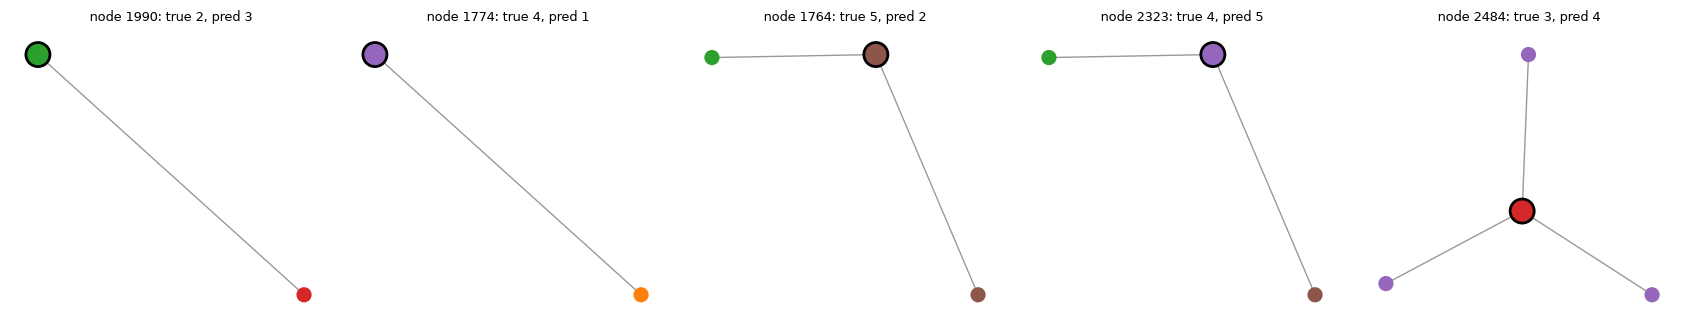

In [10]:
GNN = results[results.model != "MLP"].groupby("model").val.mean().idxmax()   # chosen on VALIDATION
print("analysing:", GNN)
err = error_analysis(runs[GNN][0]["model"], runs["MLP"][0]["model"], data, k=5)
display(err)
viz.plot_ego(data, err)

## 7. Interpretation & recommendation

**Best model.** GCN is best on test accuracy (0.820 ± 0.004) and macro F1 (0.807 ± 0.002). All three GNNs beat the MLP (0.587 ± 0.003) by about 20 points, far more than seed variation. The differences between GNNs are small: GCN vs GAT (0.807 ± 0.013) is about one GAT standard deviation, so it is not clearly significant with 3 seeds; GCN vs GraphSAGE (0.802 ± 0.005) is a small but more consistent gap. With only 140 training labels, features alone overfit (MLP train loss ~0.1, val acc ~0.58), while neighbours add information because Cora is strongly homophilous.

**Cost.** GCN has the same parameter count as the MLP (46,119) and the shortest GNN training time (13.5 s). GraphSAGE needs twice the parameters (92,199) and was slowest (34 s) without a gain. GAT has fewest parameters (23,109) but a higher per-epoch cost and the highest seed variance. Training time mostly reflects early stopping (the MLP ran all 200 epochs), so per-epoch cost is the fairer comparison.

**Depth.** Accuracy declined gently with depth for GCN (0.820 at 2 layers to ~0.76-0.78 at 6-8) and GraphSAGE (0.803 to 0.758), whose separate self-weight likely retains node information. GAT collapsed at 8 layers (0.56, very high variance), pointing to optimisation difficulty in deep attention stacks without residuals. Unexpectedly, mean pairwise cosine similarity decreased with depth (GCN 0.645 to ~0.15-0.2) instead of rising as classic over-smoothing predicts. I think this partly reflects the metric: 2-layer ELU embeddings share a large common component, and trained deeper models do not fully collapse. A centred measure (or MAD) would be needed to confirm.

**Edge removal.** The MLP is flat (0.587), confirming the control. GCN drops from 0.820 to 0.767 at 50% removal and 0.648 at 90%, still above the MLP, so even a few edges help. At 100% removal all GNNs fall to MLP level (0.57-0.59), as expected. GraphSAGE degrades fastest and meets the MLP around 75-90% removal; GCN and GAT only at 100%.

**Errors.** The 5 most confident errors all have low degree (1-3), so one neighbour dominates the aggregation. In four, the neighbours' true labels differ from the node's (heterophily); in node 1764 the MLP was right and the GNN was misled by neighbours that were themselves misclassified. Nodes 1990 and 2323 have only 5 words, giving little feature evidence, and three of the five were also missed by the MLP (ambiguous features). Confidence is low (0.44-0.60), so a confidence threshold could flag such cases. The confusion matrix shows class 0 is over-predicted (precision ~0.61) and classes 5 and 6 have the lowest recall.

**Recommendation.** Use a 2-layer GCN: best accuracy and F1, lowest seed variance, cheapest GNN, robust to modest edge loss. Attention (GAT) and sampling aggregation (GraphSAGE) gave no measurable benefit on this small homophilous graph. Use the MLP only if edges are unavailable or unreliable. Limitations: one public split, 3 seeds, 8 tuning trials per model, std computed with ddof=0.

## 8. Run the automated tests

In [2]:
!pytest ../tests/test_assignment2.py -q

.....................                                                    [100%]
============================== warnings summary ===============================
..\.venv\Lib\site-packages\torch\jit\_script.py:1491
  C:\Users\PC\Documents\GNN-practical-assignments\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
    warnings.warn(

tests/test_assignment2.py: 578 warnings
  C:\Users\PC\Documents\GNN-practical-assignments\.venv\Lib\site-packages\torch_geometric\inspector.py:433: DeprecationWarning: Failing to pass a value to the 'type_params' parameter of 'typing._eval_type' is deprecated, as it leads to incorrect behaviour when calling typing._eval_type on a stringified annotation that references a PEP 695 type parameter. It will be disallowed in Python 3.15.
    return typing._eval_type(value, _globals, None)  # type: ignore

tests/test_assignment2.py::test_error_analysis_columns
  c:\U